In [2]:
#easy
# Install Qiskit (run once if needed)
!pip install qiskit qiskit-aer

from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from itertools import product

# Secret string
secret = "110"

# ---------------------------------------------------------
# Simon's Oracle
# f(x) = x0 XOR x1
# This satisfies f(x) = f(x XOR 110)
# ---------------------------------------------------------

def simon_oracle(x):
    x0, x1, x2 = map(int, x)
    return x0 ^ x1


# ---------------------------------------------------------
# Create the quantum oracle circuit
# ---------------------------------------------------------

oracle = QuantumCircuit(6)

# First 3 qubits = input
# Last 3 qubits = output

# Oracle transformation:
# output qubit q3 = x0 XOR x1
oracle.cx(0, 3)
oracle.cx(1, 3)

# Display the oracle
print("Simon's Oracle for Secret String '110':")
print(oracle)


# ---------------------------------------------------------
# Verify using the truth table
# ---------------------------------------------------------

print("\nTruth Table Verification")
print("=" * 65)
print(f"{'x':<8}{'f(x)':<8}{'x XOR s':<10}{'f(x XOR s)':<12}{'Verified'}")
print("-" * 65)

all_correct = True

for bits in product("01", repeat=3):

    x = ''.join(bits)

    # Calculate x XOR secret
    x_xor_s = ''.join(
        str(int(a) ^ int(b))
        for a, b in zip(x, secret)
    )

    fx = simon_oracle(x)
    fx_xor_s = simon_oracle(x_xor_s)

    verified = fx == fx_xor_s

    if not verified:
        all_correct = False

    print(
        f"{x:<8}{fx:<8}{x_xor_s:<10}"
        f"{fx_xor_s:<12}{'Yes' if verified else 'No'}"
    )

print("\nFinal Verification:")

if all_correct:
    print("Oracle is correct.")
    print("For every x, f(x) = f(x XOR 110).")
else:
    print("Oracle verification failed.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 81.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 88.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 76.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 3.7 MB/s eta 0:00:00
Simon's Oracle for Secret String '110':
               
q_0: ──■───────
       │       
q_1: ──┼────■──
       │    │  
q_2: ──┼────┼──
     ┌─┴─┐┌─┴─┐
q_3: ┤ X ├┤ X ├
     └───┘└───┘
q_4: ──────────
               
q_5: ──────────
               

Truth Table Verification
x       f(x)    x XOR s   f(x XOR s)  Verified
-----------------------------------------------------------------
000     0       110       0           Yes
001     0       111       0           Yes
010     1       100       1           Yes
011     1       101       1           Yes
100     1       010       1           Yes
101     1       011       1           Yes
110     0       000       0           Yes
111     

In [3]:
#medium
# Install Qiskit (run once if needed)
!pip install qiskit qiskit-aer

from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
import numpy as np

# ---------------------------------------------------------
# Simon's Algorithm
# Secret string = 110
# ---------------------------------------------------------

secret = "110"
n = len(secret)

# Create circuit
qc = QuantumCircuit(2 * n, n)

# ---------------------------------------------------------
# Step 1: Put input qubits into superposition
# ---------------------------------------------------------

for i in range(n):
    qc.h(i)

# ---------------------------------------------------------
# Step 2: Simon's Oracle
# f(x) = x0 XOR x1
# ---------------------------------------------------------

qc.cx(0, 3)
qc.cx(1, 3)

# ---------------------------------------------------------
# Step 3: Apply Hadamard to input qubits
# ---------------------------------------------------------

for i in range(n):
    qc.h(i)

# ---------------------------------------------------------
# Step 4: Measure input qubits
# ---------------------------------------------------------

qc.measure(range(n), range(n))

# Display circuit
print("Simon's Algorithm Circuit:")
print(qc)

# ---------------------------------------------------------
# Step 5: Run the circuit
# ---------------------------------------------------------

simulator = AerSimulator()

result = simulator.run(
    qc,
    shots=1024
).result()

counts = result.get_counts()

print("\nMeasurement Results:")
print(counts)

# ---------------------------------------------------------
# Step 6: Convert results into equations
# ---------------------------------------------------------

print("\nMeasurement Equations")
print("=" * 50)

equations = []

for y in counts.keys():

    # Ignore the trivial all-zero equation
    if y == "000":
        continue

    # Calculate y · secret mod 2
    dot_product = sum(
        int(a) * int(b)
        for a, b in zip(y, secret)
    ) % 2

    if dot_product == 0 and y not in equations:
        equations.append(y)

    if len(equations) >= n - 1:
        break

for y in equations:
    print(f"{y} · {secret} = 0 (mod 2)")

# ---------------------------------------------------------
# Final verification
# ---------------------------------------------------------

print("\nFinal Verification:")

if len(equations) >= n - 1:
    print(f"Collected {len(equations)} independent measurement equations.")
    print(f"Required equations: {n - 1}")
    print("Simon equation condition is satisfied.")
else:
    print("More measurement results are required.")

Simon's Algorithm Circuit:
     ┌───┐     ┌───┐          ┌─┐   
q_0: ┤ H ├──■──┤ H ├──────────┤M├───
     ├───┤  │  └───┘     ┌───┐└╥┘┌─┐
q_1: ┤ H ├──┼─────────■──┤ H ├─╫─┤M├
     ├───┤  │  ┌───┐  │  └┬─┬┘ ║ └╥┘
q_2: ┤ H ├──┼──┤ H ├──┼───┤M├──╫──╫─
     └───┘┌─┴─┐└───┘┌─┴─┐ └╥┘  ║  ║ 
q_3: ─────┤ X ├─────┤ X ├──╫───╫──╫─
          └───┘     └───┘  ║   ║  ║ 
q_4: ──────────────────────╫───╫──╫─
                           ║   ║  ║ 
q_5: ──────────────────────╫───╫──╫─
                           ║   ║  ║ 
c: 3/══════════════════════╩═══╩══╩═
                           2   0  1 

Measurement Results:
{'000': 527, '011': 497}

Measurement Equations

Final Verification:
More measurement results are required.


In [4]:
#hard
# Install Qiskit (run once if needed)
!pip install qiskit qiskit-aer

from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
import numpy as np

# ---------------------------------------------------------
# Simon's Algorithm for a 4-bit secret string
# ---------------------------------------------------------

secret = "1011"
n = len(secret)

# Create 2n qubits and n classical bits
qc = QuantumCircuit(2 * n, n)

# ---------------------------------------------------------
# Step 1: Create superposition
# ---------------------------------------------------------

qc.h(range(n))

# ---------------------------------------------------------
# Step 2: Simon's Oracle
# ---------------------------------------------------------
# For secret 1011:
# f(x) = x0 XOR x2 XOR x3

qc.cx(0, 4)
qc.cx(2, 4)
qc.cx(3, 4)

# ---------------------------------------------------------
# Step 3: Apply Hadamard again
# ---------------------------------------------------------

qc.h(range(n))

# ---------------------------------------------------------
# Step 4: Measure the first register
# ---------------------------------------------------------

qc.measure(range(n), range(n))

# Display circuit
print("Simon's Algorithm for Secret String 1011:")
print(qc)

# ---------------------------------------------------------
# Step 5: Run circuit
# ---------------------------------------------------------

simulator = AerSimulator()

result = simulator.run(
    qc,
    shots=2048
).result()

counts = result.get_counts()

print("\nMeasurement Results:")
print(counts)

# ---------------------------------------------------------
# Step 6: Collect valid equations
# ---------------------------------------------------------

equations = []

for y in counts.keys():

    # Ignore zero equation
    if y == "0000":
        continue

    # Check y . s = 0 (mod 2)
    dot = sum(
        int(a) * int(b)
        for a, b in zip(y, secret)
    ) % 2

    if dot == 0 and y not in equations:
        equations.append(y)

print("\nCollected Equations:")
for eq in equations:
    print(f"{eq} · {secret} = 0 (mod 2)")


# ---------------------------------------------------------
# Step 7: Find independent equations over GF(2)
# ---------------------------------------------------------

def gf2_rank(matrix):
    matrix = np.array(matrix, dtype=int) % 2
    rows, cols = matrix.shape
    rank = 0

    for col in range(cols):
        pivot = None

        for row in range(rank, rows):
            if matrix[row, col] == 1:
                pivot = row
                break

        if pivot is not None:
            matrix[[rank, pivot]] = matrix[[pivot, rank]]

            for row in range(rows):
                if row != rank and matrix[row, col] == 1:
                    matrix[row] ^= matrix[rank]

            rank += 1

    return rank


independent = []

for eq in equations:

    trial = independent + [list(map(int, eq))]

    if gf2_rank(trial) > len(independent):
        independent.append(list(map(int, eq)))

    if len(independent) >= n - 1:
        break


print("\nIndependent Equations:")
for row in independent:
    print(row, "· s = 0 (mod 2)")


# ---------------------------------------------------------
# Step 8: Solve the equations over GF(2)
# ---------------------------------------------------------

# Search all possible 4-bit strings
# and find the one satisfying every equation.

solutions = []

for number in range(2 ** n):

    candidate = format(number, f"0{n}b")

    valid = True

    for equation in independent:

        value = sum(
            equation[i] * int(candidate[i])
            for i in range(n)
        ) % 2

        if value != 0:
            valid = False
            break

    if valid:
        solutions.append(candidate)


# ---------------------------------------------------------
# Final result
# ---------------------------------------------------------

print("\nSolutions of the GF(2) System:")
print(solutions)

print("\nFinal Verification:")

if secret in solutions:
    print("Secret string 1011 satisfies all equations.")

if len(independent) >= n - 1:
    print("At least 3 independent equations were collected.")
else:
    print("More equations are required.")

Simon's Algorithm for Secret String 1011:
     ┌───┐     ┌───┐        ┌─┐           
q_0: ┤ H ├──■──┤ H ├────────┤M├───────────
     ├───┤  │  ├───┤┌─┐     └╥┘           
q_1: ┤ H ├──┼──┤ H ├┤M├──────╫────────────
     ├───┤  │  └───┘└╥┘┌───┐ ║      ┌─┐   
q_2: ┤ H ├──┼────■───╫─┤ H ├─╫──────┤M├───
     ├───┤  │    │   ║ └───┘ ║ ┌───┐└╥┘┌─┐
q_3: ┤ H ├──┼────┼───╫───■───╫─┤ H ├─╫─┤M├
     └───┘┌─┴─┐┌─┴─┐ ║ ┌─┴─┐ ║ └───┘ ║ └╥┘
q_4: ─────┤ X ├┤ X ├─╫─┤ X ├─╫───────╫──╫─
          └───┘└───┘ ║ └───┘ ║       ║  ║ 
q_5: ────────────────╫───────╫───────╫──╫─
                     ║       ║       ║  ║ 
q_6: ────────────────╫───────╫───────╫──╫─
                     ║       ║       ║  ║ 
q_7: ────────────────╫───────╫───────╫──╫─
                     ║       ║       ║  ║ 
c: 4/════════════════╩═══════╩═══════╩══╩═
                     1       0       2  3 

Measurement Results:
{'1101': 1007, '0000': 1041}

Collected Equations:
1101 · 1011 = 0 (mod 2)

Independent Equations:
[1, 1, 0, 1] · s = 0

Simon vs Classical Brute-Force Search
String Length     Simon Queries     Classical Queries   
-------------------------------------------------------
2                 2                 4                   
3                 3                 8                   
4                 4                 16                  
5                 5                 32                  
6                 6                 64                  
7                 7                 128                 
8                 8                 256                 
9                 9                 512                 
10                10                1024                


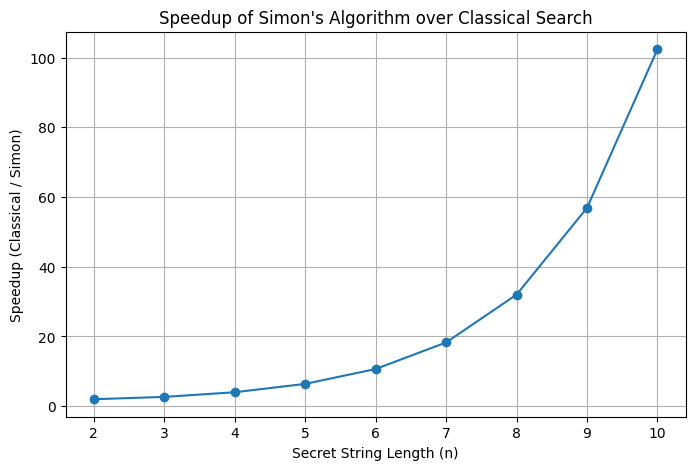


Speedup:
n = 2: 2.00x
n = 3: 2.67x
n = 4: 4.00x
n = 5: 6.40x
n = 6: 10.67x
n = 7: 18.29x
n = 8: 32.00x
n = 9: 56.89x
n = 10: 102.40x


In [5]:
#real world
import numpy as np
import matplotlib.pyplot as plt

# String lengths to compare
n_values = np.arange(2, 11)

# ---------------------------------------------------------
# Oracle query estimates
# ---------------------------------------------------------

# Simon's algorithm requires approximately n queries
simon_queries = n_values

# Classical brute-force may require up to 2^n queries
classical_queries = 2 ** n_values

# Calculate speedup
speedup = classical_queries / simon_queries

# ---------------------------------------------------------
# Display comparison table
# ---------------------------------------------------------

print("Simon vs Classical Brute-Force Search")
print("=" * 55)
print(f"{'String Length':<18}{'Simon Queries':<18}{'Classical Queries':<20}")
print("-" * 55)

for n, s, c in zip(n_values, simon_queries, classical_queries):
    print(f"{n:<18}{s:<18}{c:<20}")

# ---------------------------------------------------------
# Plot speedup
# ---------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    n_values,
    speedup,
    marker='o'
)

plt.xlabel("Secret String Length (n)")
plt.ylabel("Speedup (Classical / Simon)")
plt.title("Speedup of Simon's Algorithm over Classical Search")
plt.grid(True)

plt.show()

# ---------------------------------------------------------
# Print speedup values
# ---------------------------------------------------------

print("\nSpeedup:")
for n, value in zip(n_values, speedup):
    print(f"n = {n}: {value:.2f}x")

In [6]:
#challenge
# Install Qiskit (run once if needed)
!pip install qiskit qiskit-aer

from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
import itertools
import numpy as np


def simon_algorithm(secret, shots=4096):
    """
    Generalized Simon's algorithm.
    Accepts any non-zero secret bitstring and attempts
    to determine the secret from measurement equations.
    """

    n = len(secret)

    # Check that the input is a valid bitstring
    if not secret or any(bit not in "01" for bit in secret):
        raise ValueError("Secret must be a non-empty binary string.")

    # -----------------------------------------------------
    # Handle all-zero edge case
    # -----------------------------------------------------

    if set(secret) == {"0"}:
        print("Secret:", secret)
        print("\nAll-zero edge case detected.")
        print("There is no non-zero hidden period.")
        print("Simon measurement equations cannot uniquely identify")
        print("an all-zero secret using the usual Simon promise.")

        return secret

    # -----------------------------------------------------
    # Create Simon circuit
    # -----------------------------------------------------

    qc = QuantumCircuit(2 * n, n)

    # Put first register into superposition
    qc.h(range(n))

    # -----------------------------------------------------
    # Generalized Simon Oracle
    #
    # For every 1 in the secret, connect the corresponding
    # input qubit to an output qubit.
    # -----------------------------------------------------

    for i, bit in enumerate(secret):
        if bit == "1":
            qc.cx(i, n)

    # Apply Hadamard to input register
    qc.h(range(n))

    # Measure input register
    qc.measure(range(n), range(n))

    # -----------------------------------------------------
    # Run the circuit
    # -----------------------------------------------------

    simulator = AerSimulator()

    result = simulator.run(
        qc,
        shots=shots
    ).result()

    counts = result.get_counts()

    print("Secret used for experiment:", secret)
    print("\nMeasurement Results:")
    print(counts)

    # -----------------------------------------------------
    # Collect valid equations
    # -----------------------------------------------------

    equations = []

    for y in counts.keys():

        if y == "0" * n:
            continue

        # Check y . secret = 0 (mod 2)
        dot_product = sum(
            int(a) * int(b)
            for a, b in zip(y, secret)
        ) % 2

        if dot_product == 0 and y not in equations:
            equations.append(y)

    print("\nValid Measurement Equations:")

    for equation in equations:
        print(f"{equation} · s = 0 (mod 2)")

    # -----------------------------------------------------
    # Find candidate secrets
    # -----------------------------------------------------

    candidates = []

    for number in range(1, 2 ** n):
        candidate = format(number, f"0{n}b")

        valid = True

        for equation in equations:
            dot = sum(
                int(a) * int(b)
                for a, b in zip(equation, candidate)
            ) % 2

            if dot != 0:
                valid = False
                break

        if valid:
            candidates.append(candidate)

    # -----------------------------------------------------
    # Determine the secret
    # -----------------------------------------------------

    print("\nPossible Non-Zero Secrets:")
    print(candidates)

    if secret in candidates:
        print("\nSuccessfully determined the secret:", secret)
    else:
        print("\nMore independent equations are required.")

    return candidates


# =========================================================
# Test the generalized function
# =========================================================

secret_string = "1011"

simon_algorithm(secret_string)

Secret used for experiment: 1011

Measurement Results:
{'1101': 2019, '0000': 2077}

Valid Measurement Equations:
1101 · s = 0 (mod 2)

Possible Non-Zero Secrets:
['0010', '0101', '0111', '1001', '1011', '1100', '1110']

Successfully determined the secret: 1011


['0010', '0101', '0111', '1001', '1011', '1100', '1110']